In [6]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

np.random.seed(42)

# Fórmula de Black-Scholes (cerrada)
def bs_price(S0, K, r, sigma, T, option='call'):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option == 'call':
        return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:  # put
        return K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

# Simulación Monte Carlo bajo movimiento geométrico browniano
def mc_price(S0, K, r, sigma, T, M=10000, option='call'):
    Z = np.random.standard_normal(M)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)  # precio simulado al vencimiento

    if option == 'call':
        payoff = np.maximum(ST - K, 0)
    else:  # put
        payoff = np.maximum(K - ST, 0)

    precio = np.exp(-r * T) * np.mean(payoff)
    return precio

In [3]:
S0, K, r, sigma, T, M = 100, 100, 0.05, 0.20, 1.0, 10000

call_mc = mc_price(S0, K, r, sigma, T, M, option='call')
put_mc  = mc_price(S0, K, r, sigma, T, M, option='put')

call_bs = bs_price(S0, K, r, sigma, T, option='call')
put_bs  = bs_price(S0, K, r, sigma, T, option='put')

comparacion = pd.DataFrame({
    'Método': ['Monte Carlo', 'Black-Scholes', 'Diferencia'],
    'Call': [call_mc, call_bs, call_mc - call_bs],
    'Put':  [put_mc, put_bs, put_mc - put_bs]
})

print(comparacion)

          Método       Call       Put
0    Monte Carlo  10.450170  5.459810
1  Black-Scholes  10.450584  5.573526
2     Diferencia  -0.000414 -0.113717


In [4]:
base = dict(S0=100, K=100, r=0.05, sigma=0.20, T=1.0)

def sensibilidad(param_nombre, valores, base=base, M=10000):
    """Varía un solo parámetro (los demás quedan fijos en su valor base) y calcula el precio MC de call y put."""
    filas = []
    for v in valores:
        p = base.copy()
        p[param_nombre] = v
        call = mc_price(**p, M=M, option='call')
        put  = mc_price(**p, M=M, option='put')
        filas.append({param_nombre: v, 'call': call, 'put': put})
    return pd.DataFrame(filas)

sens_S= sensibilidad('S0',[80, 90, 100, 110, 120])
sens_K= sensibilidad('K',[80, 90, 100, 110, 120])
sens_sigma= sensibilidad('sigma',[0.10, 0.20, 0.30, 0.40, 0.50])
sens_T= sensibilidad('T',[0.25, 0.5, 1, 1.5, 2])
sens_r= sensibilidad('r',[0.05, 0.10, 0.15, 0.20])

print("Sensibilidad a S0:\n", sens_S, "\n")
print("Sensibilidad a K:\n", sens_K, "\n")
print("Sensibilidad a sigma:\n", sens_sigma, "\n")
print("Sensibilidad a T:\n", sens_T, "\n")
print("Sensibilidad a r (rendimiento):\n", sens_r)

Sensibilidad a S0:
     S0       call        put
0   80   1.771281  17.079241
1   90   5.118854  10.228477
2  100  10.558949   5.627026
3  110  17.754736   2.798992
4  120  26.383867   1.310058 

Sensibilidad a K:
      K       call        put
0   80  24.471999   0.682044
1   90  16.719390   2.233155
2  100  10.399866   5.465817
3  110   5.838473  10.656006
4  120   3.191173  17.306687 

Sensibilidad a sigma:
    sigma       call        put
0    0.1   6.865463   1.895070
1    0.2  10.351538   5.584492
2    0.3  13.994637   9.378623
3    0.4  17.982718  13.168800
4    0.5  21.617568  17.176186 

Sensibilidad a T:
       T       call       put
0  0.25   4.757198  3.416907
1  0.50   6.834469  4.405710
2  1.00  10.500226  5.518917
3  1.50  13.598361  6.343009
4  2.00  15.913310  6.676767 

Sensibilidad a r (rendimiento):
       r       call       put
0  0.05  10.699425  5.568860
1  0.10  13.146646  3.714771
2  0.15  16.210480  2.534150
3  0.20  19.717261  1.512825


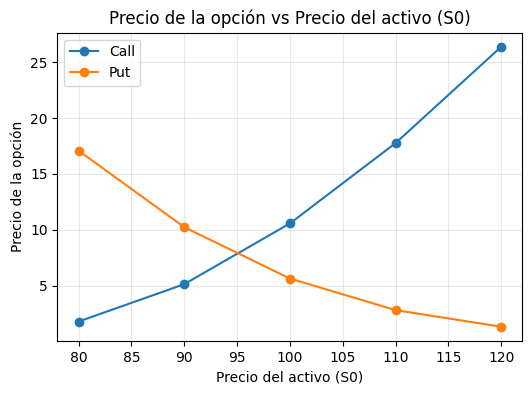

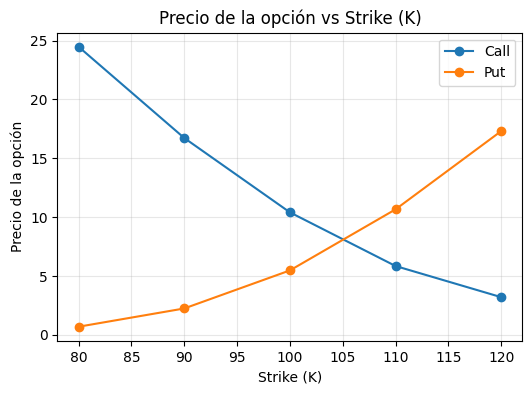

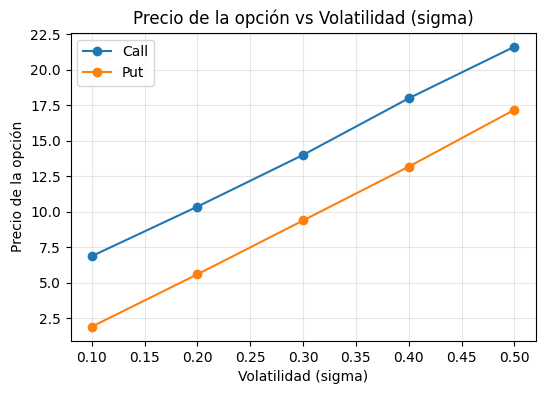

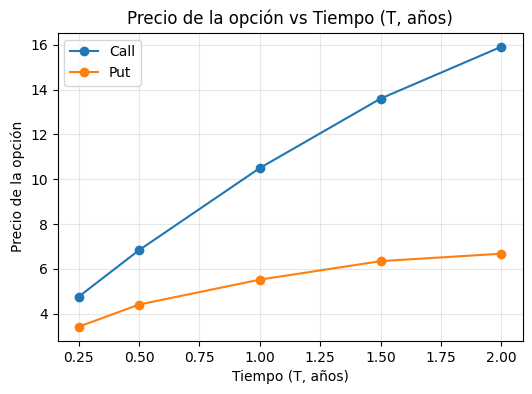

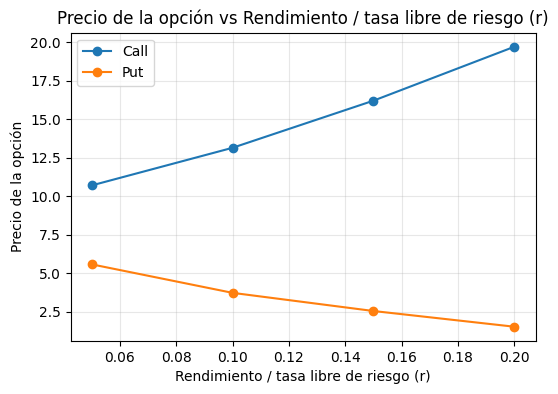

In [5]:
def graficar(df, param_nombre, etiqueta_x):
    plt.figure(figsize=(6, 4))
    plt.plot(df[param_nombre], df['call'], marker='o', label='Call')
    plt.plot(df[param_nombre], df['put'], marker='o', label='Put')
    plt.xlabel(etiqueta_x)
    plt.ylabel('Precio de la opción')
    plt.title(f'Precio de la opción vs {etiqueta_x}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

graficar(sens_S, 'S0', 'Precio del activo (S0)')
graficar(sens_K, 'K', 'Strike (K)')
graficar(sens_sigma, 'sigma', 'Volatilidad (sigma)')
graficar(sens_T, 'T', 'Tiempo (T, años)')
graficar(sens_r, 'r', 'Rendimiento / tasa libre de riesgo (r)')

# Parte 4 Interpretación

### Precio del activo

**¿Por qué la call sube cuando sube el precio de la acción?**
Porque la call te deja comprar a un precio fijo. Si la acción vale más, la diferencia a tu favor crece. Se ve claro en los datos con S0=80 la call vale 1.77, y con S0=120 sube a 26.38.

**¿Por qué la put se comporta distinto?**
En put es al revés te deja vender a un precio fijo. Si la acción sube, vender "caro" ya no sirve de nada, así que la put pierde valor. En mis resultados pasa justo eso con S0=80 la put vale 17.08, y con S0=120 cae a 1.31.

### Volatilidad

**¿Por qué más incertidumbre sube (o baja) el valor de la opción?**
La sube. Con una opción solo puedes ganar o quedarte en cero, nunca pierdes más de lo que pagaste. Entonces más incertidumbre = más chance de que el precio se mueva mucho a tu favor, sin que el "mucho en tu contra" te cueste extra. Por eso subieron las dos el call pasó de 6.87 (sigma=10%) a 21.62 (sigma=50%), y la put de 1.90 a 17.18.

### Tiempo

**¿Siempre es deseable tener más tiempo?**
No siempre, depende de en qué lado estés. La call sube de 4.76 (T=0.25) a 15.91 (T=2), y la put igual sube, aunque menos (de 3.42 a 6.68). Para el que compra la opción, más tiempo es bueno porque hay más chance de que el precio se mueva a su favor.

**¿Para quién resulta favorable?**
Para el comprador (el tenedor) de la opción. Para el que la vendió es al revés se queda expuesto más tiempo sin cobrar nada extra por eso.

### Strike

**¿Cómo modifica el strike la probabilidad de terminar in-the-money?**
Entre más bajo el strike, más fácil que la call termine in-the-money (y más difícil para la put), entre más alto, es al revés. Se ve en mis números: con K=80 la call vale 24.47 y la put casi nada (0.68); con K=120 se invierte, call=3.19 y put=17.31.

**Definir in-the-money.**
Es cuando, si la opción venciera justo ahora, te convendría ejercerla porque te daría dinero. En una call pasa cuando el precio del activo es mayor al strike (S>K); en una put, cuando es menor (S<K).

# Parte 5 Comparación con el mercado

Si fuera inversionista, el parámetro que más vigilaría es la **volatilidad**. Es la única que sube el precio de la call y de la put al mismo tiempo (los demás parámetros mueven una hacia arriba y la otra hacia abajo), y además no se puede saber con certeza cuál va a ser, solo se estima. En mis resultados, moverla de 10% a 50% casi triplica el precio de la call y multiplica casi por 9 el de la put, o sea que si te equivocas al estimarla, el error se nota muchísimo en el precio final de la opción.